# Proyecto Final · Interconnect Customer Churn Prediction 
## SANTIAGO PARADA

**Proyecto final de Data Science · TripleTen · Sprint 19**  
**Problema:** clasificación binaria del abandono de clientes  
**Métrica principal:** AUC-ROC  
**Métrica adicional:** Recall

Este notebook integra el análisis del cliente, una segmentación comercial mediante clustering y un modelo para estimar el riesgo de abandono.

## Resumen ejecutivo

Interconnect desea anticipar qué clientes tienen mayor probabilidad de cancelar para priorizar acciones de retención. El proyecto integra cuatro fuentes, analiza el mercado, construye tres segmentos comerciales y desarrolla un modelo predictivo sin utilizar `BeginDate` ni `EndDate` como características.

La primera solución, basada en regresión logística, obtuvo un AUC-ROC de **0,809** en prueba. Ese resultado se conservó como referencia y justificó continuar con Gradient Boosting.

El modelo final obtuvo un AUC-ROC de **0,860 en validación** y **0,837 en prueba**, mejorando **0,029** frente a la solución provisional. Con un umbral de **0,35**, alcanzó un recall de **0,741**, una precisión de **0,544** y detectó **277 de 374** cancelaciones del conjunto de prueba.

El clustering y la predicción cuentan una historia coherente: los segmentos de riesgo bajo, alto e intermedio también reciben probabilidades medias bajas, altas e intermedias. Marketing puede utilizar los clusters para adaptar el mensaje y las probabilidades para ordenar la prioridad de contacto.

# Etapa 1 · Plan de trabajo

## 1. Objetivo y estrategia

Interconnect desea identificar clientes con mayor riesgo de cancelar sus servicios para orientar acciones de retención. El estudio tiene dos componentes:

- **Análisis del cliente y del mercado:** comprender la cartera, los servicios contratados y los perfiles comerciales.
- **Predicción:** estimar la probabilidad de abandono mediante clasificación binaria.

`Churn` será igual a `1` cuando exista una fecha de cancelación y `0` cuando `EndDate` sea `"No"`. AUC-ROC será la métrica principal y Recall será la métrica adicional.

## 2. Integración y calidad

`contract.csv` será la tabla principal. `personal.csv`, `internet.csv` y `phone.csv` se unirán por `customerID` mediante un `left merge` uno a uno.

Después de cada unión se comprobará que:

- se mantienen los 7.043 clientes;
- `customerID` continúa siendo único;
- no se multiplican filas;
- las ausencias de internet y telefonía se interpretan como servicios no contratados, no como errores.

## 3. Análisis de mercado y clustering

Se resumirán los hallazgos esenciales sobre contrato, tecnología, pagos, cargos, servicios y características personales. Después se construirá un clustering comercial sin utilizar `Churn`.

El clustering responderá **qué tipos de clientes existen**. Una vez creados los grupos, se calculará su abandono histórico para describirlos. El modelo supervisado responderá una pregunta diferente: **qué clientes presentan mayor probabilidad de cancelar**.

## 4. Características y prevención de fuga

Las variables categóricas nominales se transforman mediante `OneHotEncoder`; las binarias se convierten a `0/1`; los cargos se estandarizan dentro del `Pipeline`.

Se excluyen `customerID`, `EndDate`, `BeginDate` y cualquier duración calculada con fechas. `EndDate` contiene directamente la respuesta y `BeginDate` no se incorpora porque el escenario de observación temporal no está suficientemente documentado.

La solución inicial también excluye `TotalCharges`. En la etapa final se incorpora como dato de facturación acumulada conocido al momento de analizar al cliente, sin calcular duración ni utilizar fechas. Sus once valores vacíos, correspondientes a cuentas sin historial de cobro, se completan con cero.

Primero se dividen los datos. El One-Hot, el escalado y los modelos se ajustan únicamente con entrenamiento mediante un `Pipeline`.

## 5. División, modelos y evaluación

Se crean conjuntos estratificados de entrenamiento, validación y prueba. Primero se comparan `LogisticRegression` y `RandomForestClassifier`, sin balanceo y con ajustes controlados. Como esta solución queda por debajo del objetivo, se añade una búsqueda breve y visible de `GradientBoostingClassifier`.

Los parámetros y el umbral se eligen con validación. El mismo conjunto de prueba permite comparar la mejora final con la referencia inicial bajo las mismas condiciones. Se reportan AUC-ROC, recall, precisión, F1, matriz de confusión y curva ROC.

Finalmente se comparan los clusters con las probabilidades del modelo para comprobar si los segmentos con mayor abandono histórico también concentran mayor riesgo predicho.

# Etapa 2 · Código de solución

## A. Preparación del entorno

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
    silhouette_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEMILLA = 42
COLOR_AZUL = "#3B6B86"
COLOR_NARANJA = "#D97745"
COLOR_GRIS = "#6B7280"

plt.style.use("default")
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25
pd.set_option("display.max_columns", 40)

def crear_one_hot_encoder():
    # Compatible con versiones nuevas y antiguas de scikit-learn.
    try:
        return OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False,
        )
    except TypeError:
        return OneHotEncoder(
            handle_unknown="ignore",
            sparse=False,
        )


## B. Carga y comprobación de los datos

El notebook puede ejecutarse desde la raíz del repositorio, desde `notebooks/` o en el entorno de TripleTen.

In [2]:
nombres_archivos = ["contract.csv", "personal.csv", "internet.csv", "phone.csv"]

rutas_posibles = [
    Path.cwd() / "data" / "raw",
    Path.cwd().parent / "data" / "raw",
    Path("/datasets/final_provider"),
]

for ruta in rutas_posibles:
    if all((ruta / archivo).exists() for archivo in nombres_archivos):
        RUTA_DATOS = ruta
        break
else:
    raise FileNotFoundError("No se encontraron los cuatro CSV originales.")

print("Fuentes de datos localizadas correctamente.")

Fuentes de datos localizadas correctamente.


In [3]:
contract = pd.read_csv(RUTA_DATOS / "contract.csv")
personal = pd.read_csv(RUTA_DATOS / "personal.csv")
internet = pd.read_csv(RUTA_DATOS / "internet.csv")
phone = pd.read_csv(RUTA_DATOS / "phone.csv")

tablas = {
    "contract": contract,
    "personal": personal,
    "internet": internet,
    "phone": phone,
}

In [4]:
auditoria = []

for nombre, tabla in tablas.items():
    auditoria.append({
        "Tabla": nombre,
        "Filas": len(tabla),
        "Columnas": tabla.shape[1],
        "Clientes únicos": tabla["customerID"].nunique(),
        "IDs duplicados": tabla["customerID"].duplicated().sum(),
        "Celdas nulas": tabla.isna().sum().sum(),
    })

auditoria = pd.DataFrame(auditoria)
display(auditoria)

,Tabla,Filas,Columnas,Clientes únicos,IDs duplicados,Celdas nulas
0,contract,7043,8,7043,0,0
1,personal,7043,5,7043,0,0
2,internet,5517,8,5517,0,0
3,phone,6361,2,6361,0,0


In [5]:
ids_contrato = set(contract["customerID"])

assert contract["customerID"].is_unique
assert personal["customerID"].is_unique
assert internet["customerID"].is_unique
assert phone["customerID"].is_unique

assert set(personal["customerID"]) == ids_contrato
assert set(internet["customerID"]).issubset(ids_contrato)
assert set(phone["customerID"]).issubset(ids_contrato)

print("Integridad de identificadores: correcta")

Integridad de identificadores: correcta


## C. Integración de las cuatro fuentes

In [6]:
clientes = contract.copy()

for nombre in ["personal", "internet", "phone"]:
    clientes = clientes.merge(
        tablas[nombre],
        on="customerID",
        how="left",
        validate="one_to_one",
        indicator=f"_merge_{nombre}",
    )

assert len(clientes) == len(contract)
assert clientes["customerID"].is_unique

print("Dimensiones después de las uniones:", clientes.shape)

Dimensiones después de las uniones: (7043, 23)


### Ausencias estructurales

Primero distinguimos si el cliente aparece en las tablas opcionales. Solo después rellenamos las categorías que significan servicio no contratado.

In [7]:
clientes["TieneInternet"] = clientes["_merge_internet"].eq("both").astype(int)
clientes["TieneTelefono"] = clientes["_merge_phone"].eq("both").astype(int)

assert clientes["_merge_personal"].eq("both").all()
assert (clientes["TieneInternet"] + clientes["TieneTelefono"]).ge(1).all()

servicios_internet = [
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
]

columnas_internet = ["InternetService", *servicios_internet]

assert clientes.loc[clientes["TieneInternet"].eq(1), columnas_internet].notna().all().all()
assert clientes.loc[clientes["TieneTelefono"].eq(1), "MultipleLines"].notna().all()

clientes.loc[clientes["TieneInternet"].eq(0), "InternetService"] = "No"
clientes.loc[clientes["TieneInternet"].eq(0), servicios_internet] = "No internet service"
clientes.loc[clientes["TieneTelefono"].eq(0), "MultipleLines"] = "No phone service"

clientes = clientes.drop(columns=[
    "_merge_personal", "_merge_internet", "_merge_phone"
])

In [8]:
perfil_servicios = (
    clientes.groupby(["TieneInternet", "TieneTelefono"])
    .size()
    .rename("Clientes")
    .reset_index()
)

perfil_servicios["Perfil"] = perfil_servicios.apply(
    lambda fila: "Ambos"
    if fila["TieneInternet"] == 1 and fila["TieneTelefono"] == 1
    else "Solo internet"
    if fila["TieneInternet"] == 1
    else "Solo teléfono",
    axis=1,
)

display(perfil_servicios[["Perfil", "Clientes"]])

,Perfil,Clientes
0,Solo teléfono,1526
1,Solo internet,682
2,Ambos,4835


## D. Objetivo e ingeniería de características

In [9]:
fechas_cancelacion = pd.to_datetime(
    clientes.loc[clientes["EndDate"].ne("No"), "EndDate"],
    errors="coerce",
)

assert fechas_cancelacion.notna().all()

clientes["Churn"] = clientes["EndDate"].ne("No").astype(int)
clientes["BeginDate"] = pd.to_datetime(clientes["BeginDate"], errors="raise")
clientes["TotalCharges"] = pd.to_numeric(
    clientes["TotalCharges"].astype(str).str.strip(),
    errors="coerce",
)

print("Clientes:", len(clientes))
print("Cancelaciones:", clientes["Churn"].sum())
print(f"Tasa de abandono: {clientes['Churn'].mean():.2%}")
print("TotalCharges vacíos:", clientes["TotalCharges"].isna().sum())

Clientes: 7043
Cancelaciones: 1869
Tasa de abandono: 26.54%
TotalCharges vacíos: 11


In [10]:
clientes["NumServiciosInternet"] = (
    clientes[servicios_internet].eq("Yes").sum(axis=1)
)

clientes["SeguridadYSoporte"] = (
    clientes["OnlineSecurity"].eq("Yes")
    & clientes["TechSupport"].eq("Yes")
).astype(int)

clientes["StreamingCompleto"] = (
    clientes["StreamingTV"].eq("Yes")
    & clientes["StreamingMovies"].eq("Yes")
).astype(int)

clientes[[
    "TieneInternet", "TieneTelefono", "NumServiciosInternet",
    "SeguridadYSoporte", "StreamingCompleto"
]].head()

,TieneInternet,TieneTelefono,NumServiciosInternet,SeguridadYSoporte,StreamingCompleto
0,1,0,1,0,0
1,1,1,2,0,0
2,1,1,2,0,0
3,1,0,3,1,0
4,1,1,0,0,0


## E. Análisis exploratorio esencial

,Clientes
Churn,
Permanece,5174
Cancela,1869


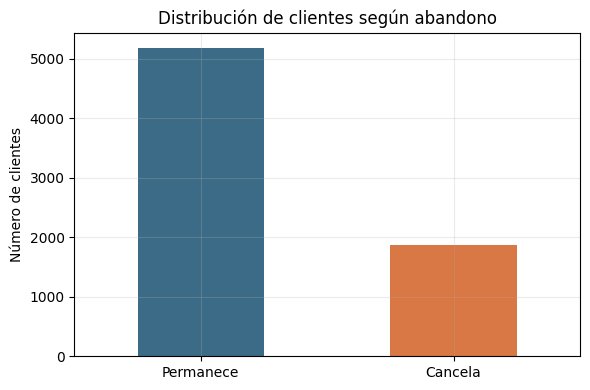

In [11]:
distribucion_churn = (
    clientes["Churn"]
    .value_counts()
    .sort_index()
    .rename(index={0: "Permanece", 1: "Cancela"})
)

display(distribucion_churn.rename("Clientes").to_frame())

ax = distribucion_churn.plot(
    kind="bar",
    color=[COLOR_AZUL, COLOR_NARANJA],
    figsize=(6, 4),
    rot=0,
)
ax.set_title("Distribución de clientes según abandono")
ax.set_xlabel("")
ax.set_ylabel("Número de clientes")
plt.tight_layout()
plt.show()

In [12]:
def resumen_churn(columna):
    resumen = (
        clientes.groupby(columna)["Churn"]
        .agg(Clientes="size", Cancelaciones="sum", Tasa="mean")
        .reset_index()
    )
    resumen["Tasa de churn (%)"] = resumen["Tasa"] * 100
    return resumen.drop(columns="Tasa")

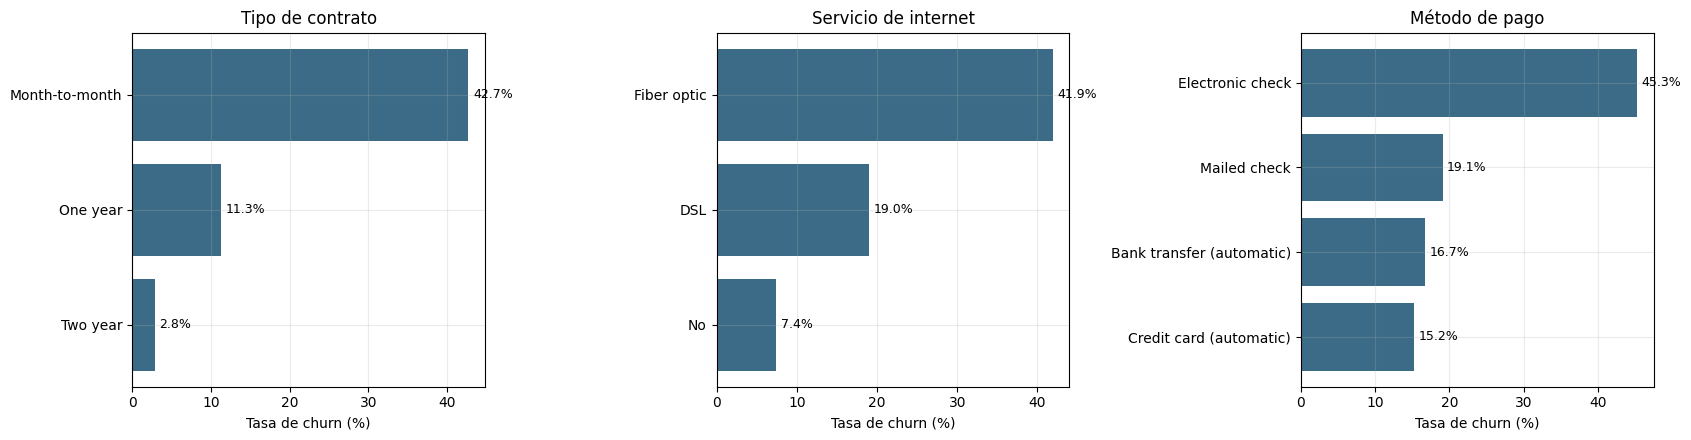

In [13]:
fig, ejes = plt.subplots(1, 3, figsize=(17, 4.5))

for columna, eje, titulo in zip(
    ["Type", "InternetService", "PaymentMethod"],
    ejes,
    ["Tipo de contrato", "Servicio de internet", "Método de pago"],
):
    tabla = resumen_churn(columna).sort_values("Tasa de churn (%)")
    eje.barh(tabla[columna], tabla["Tasa de churn (%)"], color=COLOR_AZUL)
    eje.set_title(titulo)
    eje.set_xlabel("Tasa de churn (%)")
    eje.set_ylabel("")
    for posicion, valor in enumerate(tabla["Tasa de churn (%)"]):
        eje.text(valor + 0.6, posicion, f"{valor:.1f}%", va="center", fontsize=9)

plt.tight_layout()
plt.show()

In [14]:
tabla_contrato = resumen_churn("Type")
tabla_internet = resumen_churn("InternetService")
tabla_pago = resumen_churn("PaymentMethod")

display(tabla_contrato.round(2))
display(tabla_internet.round(2))
display(tabla_pago.round(2))

,Type,Clientes,Cancelaciones,Tasa de churn (%)
0,Month-to-month,3875,1655,42.71
1,One year,1473,166,11.27
2,Two year,1695,48,2.83


,InternetService,Clientes,Cancelaciones,Tasa de churn (%)
0,DSL,2421,459,18.96
1,Fiber optic,3096,1297,41.89
2,No,1526,113,7.40


,PaymentMethod,Clientes,Cancelaciones,Tasa de churn (%)
0,Bank transfer (automatic),1544,258,16.71
1,Credit card (automatic),1522,232,15.24
2,Electronic check,2365,1071,45.29
3,Mailed check,1612,308,19.11


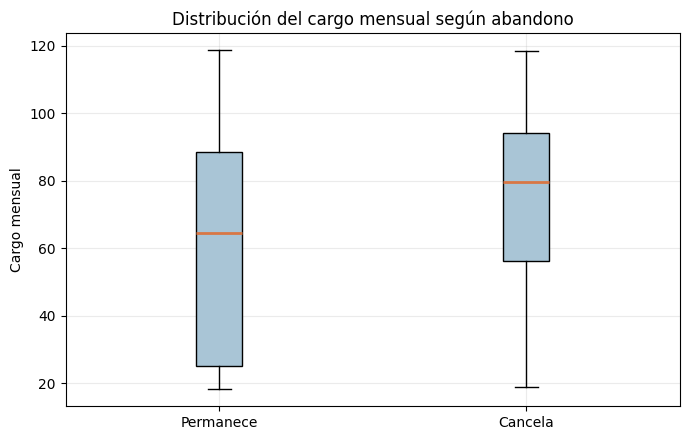

In [15]:
fig, eje = plt.subplots(figsize=(7, 4.5))

eje.boxplot(
    [
        clientes.loc[clientes["Churn"].eq(0), "MonthlyCharges"],
        clientes.loc[clientes["Churn"].eq(1), "MonthlyCharges"],
    ],
    patch_artist=True,
    boxprops={"facecolor": "#A9C5D6"},
    medianprops={"color": COLOR_NARANJA, "linewidth": 2},
)

eje.set_xticks([1, 2])
eje.set_xticklabels(["Permanece", "Cancela"])

eje.set_title("Distribución del cargo mensual según abandono")
eje.set_xlabel("")
eje.set_ylabel("Cargo mensual")
plt.tight_layout()
plt.show()

In [16]:
resumen_personal = pd.concat(
    [
        resumen_churn("gender").assign(Variable="gender"),
        resumen_churn("SeniorCitizen").assign(Variable="SeniorCitizen"),
    ],
    ignore_index=True,
)

display(resumen_personal.round(2))

,gender,Clientes,Cancelaciones,Tasa de churn (%),Variable,SeniorCitizen
0,Female,3488,939,26.92,gender,NaN
1,Male,3555,930,26.16,gender,NaN
2,NaN,5901,1393,23.61,SeniorCitizen,0.0
3,NaN,1142,476,41.68,SeniorCitizen,1.0


**Lectura del EDA:** las tasas observadas describen asociaciones históricas. No demuestran que un contrato, una tecnología o una característica personal causen el abandono.

## F. Segmentación comercial mediante clustering

El clustering utiliza contrato, pago, tecnología, facturación, servicios y cargo mensual. `Churn`, las fechas y los atributos personales no participan en la creación de grupos.

In [17]:
variables_cluster = [
    "Type", "PaymentMethod", "InternetService", "PaperlessBilling",
    "MultipleLines", *servicios_internet, "MonthlyCharges",
]

datos_cluster = clientes[variables_cluster].copy()

columnas_si_no = ["PaperlessBilling", "MultipleLines", *servicios_internet]
for columna in columnas_si_no:
    datos_cluster[columna] = datos_cluster[columna].eq("Yes").astype(int)

datos_cluster = pd.get_dummies(
    datos_cluster,
    columns=["Type", "PaymentMethod", "InternetService"],
    dtype=int,
)

escalador_cluster = StandardScaler()
datos_cluster["MonthlyCharges"] = escalador_cluster.fit_transform(
    datos_cluster[["MonthlyCharges"]]
)

print("Variables utilizadas:", datos_cluster.shape[1])
print("Churn incluido:", "Churn" in datos_cluster.columns)

Variables utilizadas: 19
Churn incluido: False


In [18]:
resultados_k = []

for k in range(2, 7):
    modelo_k = KMeans(n_clusters=k, random_state=SEMILLA, n_init=10)
    grupos = modelo_k.fit_predict(datos_cluster)
    silueta = silhouette_score(
        datos_cluster,
        grupos,
        sample_size=1200,
        random_state=SEMILLA,
    )
    resultados_k.append({"k": k, "Silhouette": silueta})

resultados_k = pd.DataFrame(resultados_k)
display(resultados_k.round(3))

,k,Silhouette
0,2,0.242
1,3,0.238
2,4,0.223
3,5,0.212
4,6,0.192


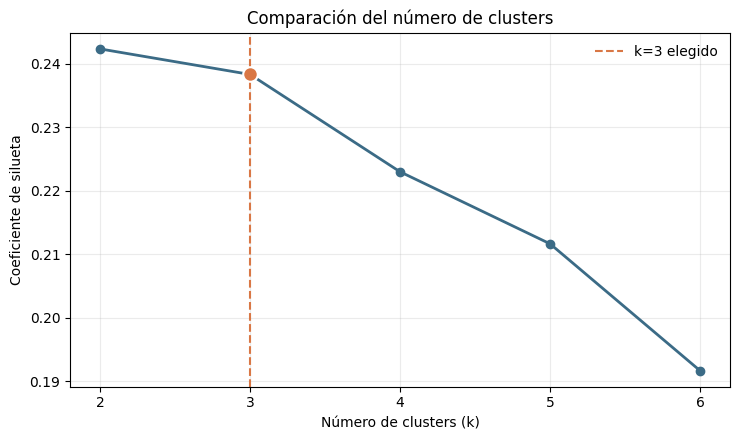

k elegido: 3
Silhouette k=2: 0.242
Silhouette k=3: 0.238
Diferencia: 0.004


In [19]:
silueta_k2 = float(
    resultados_k.loc[resultados_k["k"].eq(2), "Silhouette"].iloc[0]
)
silueta_k3 = float(
    resultados_k.loc[resultados_k["k"].eq(3), "Silhouette"].iloc[0]
)
diferencia_silueta = silueta_k2 - silueta_k3

# Se eligen tres grupos porque la pérdida de silueta es mínima
# y la segmentación resulta más útil para el análisis comercial.
k_elegido = 3

fig, eje = plt.subplots(figsize=(7.5, 4.5))
eje.plot(
    resultados_k["k"],
    resultados_k["Silhouette"],
    marker="o",
    linewidth=2,
    color=COLOR_AZUL,
)
eje.axvline(
    k_elegido,
    color=COLOR_NARANJA,
    linestyle="--",
    label="k=3 elegido",
)
eje.scatter(
    [3], [silueta_k3],
    s=110,
    color=COLOR_NARANJA,
    edgecolor="white",
    linewidth=1.5,
    zorder=3,
)
eje.set_title("Comparación del número de clusters")
eje.set_xlabel("Número de clusters (k)")
eje.set_ylabel("Coeficiente de silueta")
eje.set_xticks(resultados_k["k"])
eje.legend(frameon=False)
plt.tight_layout()
plt.show()

print("k elegido:", k_elegido)
print(f"Silhouette k=2: {silueta_k2:.3f}")
print(f"Silhouette k=3: {silueta_k3:.3f}")
print(f"Diferencia: {diferencia_silueta:.3f}")

In [20]:
modelo_cluster = KMeans(
    n_clusters=k_elegido,
    random_state=SEMILLA,
    n_init=10,
)

segmentos = clientes.copy()
segmentos["Cluster"] = modelo_cluster.fit_predict(datos_cluster) + 1

segmentos["MesAMes"] = segmentos["Type"].eq("Month-to-month").astype(int)
segmentos["Fibra"] = segmentos["InternetService"].eq("Fiber optic").astype(int)
segmentos["ChequeElectronico"] = segmentos["PaymentMethod"].eq("Electronic check").astype(int)

perfil_clusters = (
    segmentos.groupby("Cluster")
    .agg(
        Clientes=("customerID", "size"),
        Cancelaciones=("Churn", "sum"),
        Tasa_churn=("Churn", "mean"),
        Cargo_mensual=("MonthlyCharges", "mean"),
        Servicios_internet=("NumServiciosInternet", "mean"),
        Mes_a_mes=("MesAMes", "mean"),
        Fibra=("Fibra", "mean"),
        Cheque_electronico=("ChequeElectronico", "mean"),
        Adulto_mayor=("SeniorCitizen", "mean"),
    )
)

columnas_porcentaje = [
    "Tasa_churn", "Mes_a_mes", "Fibra",
    "Cheque_electronico", "Adulto_mayor",
]
perfil_clusters[columnas_porcentaje] *= 100

perfil_clusters = perfil_clusters.rename(columns={
    "Tasa_churn": "Tasa churn (%)",
    "Cargo_mensual": "Cargo mensual medio",
    "Servicios_internet": "Servicios internet medios",
    "Mes_a_mes": "Mes a mes (%)",
    "Fibra": "Fibra (%)",
    "Cheque_electronico": "Cheque electrónico (%)",
    "Adulto_mayor": "Adulto mayor (%)",
})

display(perfil_clusters.round(2))

,Clientes,Cancelaciones,Tasa churn (%),Cargo mensual medio,Servicios internet medios,Mes a mes (%),Fibra (%),Cheque electrónico (%),Adulto mayor (%)
Cluster,,,,,,,,,
1,1576,133,8.44,21.20,0.00,36.10,0.00,8.57,3.81
2,3097,1297,41.88,91.50,2.55,68.74,99.97,51.53,26.83
3,2370,439,18.52,58.79,2.72,49.66,0.00,26.75,10.59


### Mapa visual de los tres segmentos

PCA resume las variables del clustering en dos ejes para poder dibujarlas. La figura ayuda a observar la posición relativa de los grupos, pero no reemplaza las métricas ni conserva toda la información original.

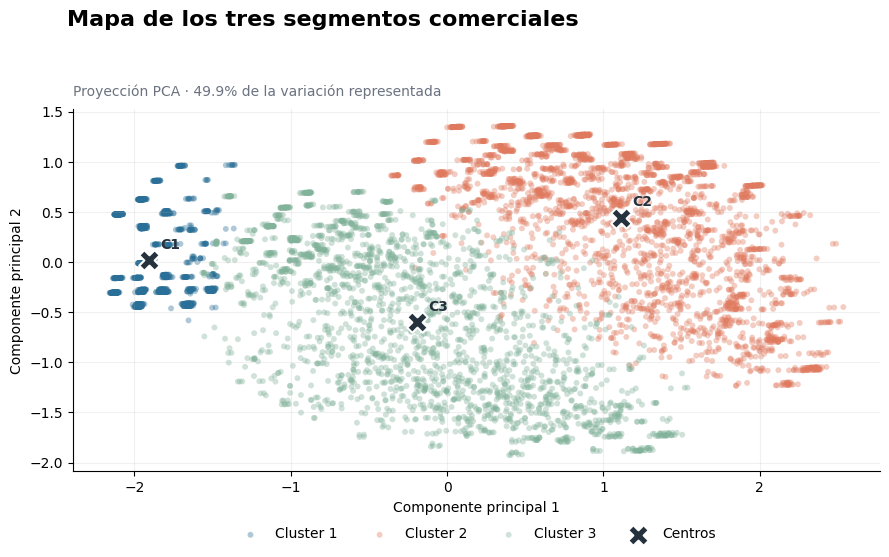

In [21]:
pca = PCA(n_components=2)
coordenadas = pca.fit_transform(datos_cluster)
centros_cluster = pd.DataFrame(
    modelo_cluster.cluster_centers_,
    columns=datos_cluster.columns,
)
centros_pca = pca.transform(centros_cluster)

mapa_segmentos = pd.DataFrame({
    "Componente 1": coordenadas[:, 0],
    "Componente 2": coordenadas[:, 1],
    "Cluster": segmentos["Cluster"],
})

colores_cluster = {
    1: "#2A6F97",
    2: "#E07A5F",
    3: "#81B29A",
}

fig, eje = plt.subplots(figsize=(9, 6))

for numero_cluster in sorted(mapa_segmentos["Cluster"].unique()):
    grupo = mapa_segmentos.loc[
        mapa_segmentos["Cluster"].eq(numero_cluster)
    ]
    eje.scatter(
        grupo["Componente 1"],
        grupo["Componente 2"],
        s=18,
        alpha=0.38,
        color=colores_cluster[numero_cluster],
        label=f"Cluster {numero_cluster}",
        edgecolors="none",
    )

eje.scatter(
    centros_pca[:, 0],
    centros_pca[:, 1],
    marker="X",
    s=220,
    color="#25313C",
    edgecolor="white",
    linewidth=1.5,
    label="Centros",
    zorder=4,
)

for indice, (x, y) in enumerate(centros_pca, start=1):
    eje.annotate(
        f"C{indice}",
        (x, y),
        xytext=(8, 8),
        textcoords="offset points",
        fontsize=10,
        fontweight="bold",
        color="#25313C",
    )

varianza_visible = pca.explained_variance_ratio_.sum() * 100

fig.suptitle(
    "Mapa de los tres segmentos comerciales",
    x=0.08,
    y=0.98,
    ha="left",
    fontsize=16,
    fontweight="bold",
)
eje.set_title(
    f"Proyección PCA · {varianza_visible:.1f}% de la variación representada",
    loc="left",
    fontsize=10,
    color=COLOR_GRIS,
    pad=10,
)
eje.set_xlabel("Componente principal 1")
eje.set_ylabel("Componente principal 2")
eje.grid(alpha=0.18)
eje.spines["top"].set_visible(False)
eje.spines["right"].set_visible(False)
eje.legend(
    frameon=False,
    ncol=4,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
)

plt.tight_layout(rect=[0, 0.04, 1, 0.94])
plt.show()

In [22]:
categorias_principales = (
    segmentos.groupby("Cluster")[["Type", "PaymentMethod", "InternetService"]]
    .agg(lambda serie: serie.mode().iat[0])
    .rename(columns={
        "Type": "Contrato más común",
        "PaymentMethod": "Pago más común",
        "InternetService": "Internet más común",
    })
)

display(categorias_principales)

,Contrato más común,Pago más común,Internet más común
Cluster,,,
1,Two year,Mailed check,No
2,Month-to-month,Electronic check,Fiber optic
3,Month-to-month,Electronic check,DSL


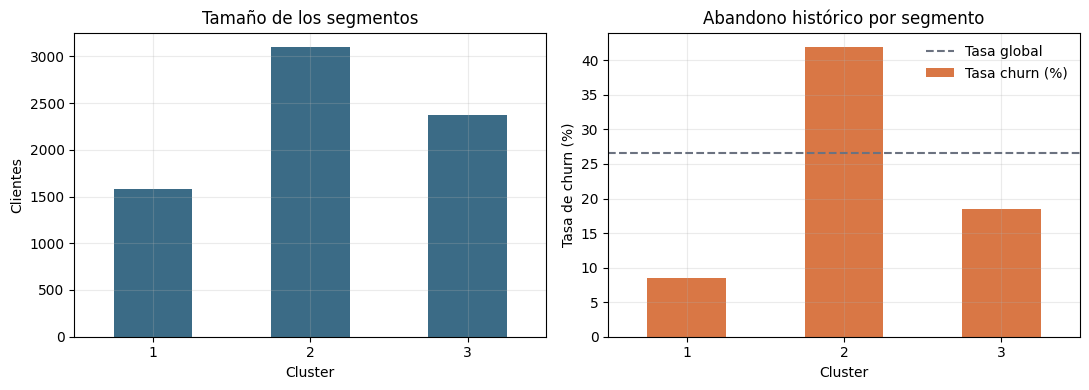

In [23]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))

perfil_clusters["Clientes"].plot(
    kind="bar", ax=ejes[0], color=COLOR_AZUL, rot=0
)
ejes[0].set_title("Tamaño de los segmentos")
ejes[0].set_xlabel("Cluster")
ejes[0].set_ylabel("Clientes")

perfil_clusters["Tasa churn (%)"].plot(
    kind="bar", ax=ejes[1], color=COLOR_NARANJA, rot=0
)
ejes[1].axhline(
    clientes["Churn"].mean() * 100,
    color=COLOR_GRIS,
    linestyle="--",
    label="Tasa global",
)
ejes[1].set_title("Abandono histórico por segmento")
ejes[1].set_xlabel("Cluster")
ejes[1].set_ylabel("Tasa de churn (%)")
ejes[1].legend(frameon=False)

plt.tight_layout()
plt.show()

**Conclusión de la segmentación.** Se eligieron **tres clusters** para disponer de perfiles comerciales más detallados. La silueta disminuye solo **0,004** frente a `k=2`, una diferencia pequeña para este objetivo descriptivo.

El cluster **2** presenta la mayor tasa histórica de abandono (**41,88 %**), mientras que el cluster **1** presenta la menor (**8,44 %**). El cluster **3** ocupa una posición intermedia (**18,52 %**).

Los grupos son perfiles comerciales aproximados. No representan fronteras perfectas ni demuestran causalidad.

### Características personales dentro de los clusters

Después de crear los segmentos con variables comerciales, analizamos cómo se distribuyen `gender`, `SeniorCitizen`, `Partner` y `Dependents` dentro de cada grupo. Estas variables ayudan a describir el público de cada segmento y no participaron en el entrenamiento de K-Means.

In [24]:
segmentos["Mujer"] = segmentos["gender"].eq("Female").astype(int)
segmentos["AdultoMayor"] = segmentos["SeniorCitizen"].astype(int)
segmentos["ConPareja"] = segmentos["Partner"].eq("Yes").astype(int)
segmentos["ConDependientes"] = segmentos["Dependents"].eq("Yes").astype(int)

perfil_publico = (
    segmentos.groupby("Cluster")[[
        "Mujer", "AdultoMayor", "ConPareja", "ConDependientes"
    ]]
    .mean()
    .mul(100)
    .rename(columns={
        "Mujer": "Mujeres (%)",
        "AdultoMayor": "Adultos mayores (%)",
        "ConPareja": "Con pareja (%)",
        "ConDependientes": "Con dependientes (%)",
    })
)

display(perfil_publico.round(2))

,Mujeres (%),Adultos mayores (%),Con pareja (%),Con dependientes (%)
Cluster,,,,
1,49.05,3.81,47.34,41.50
2,50.18,26.83,48.34,21.41
3,48.99,10.59,48.90,33.46


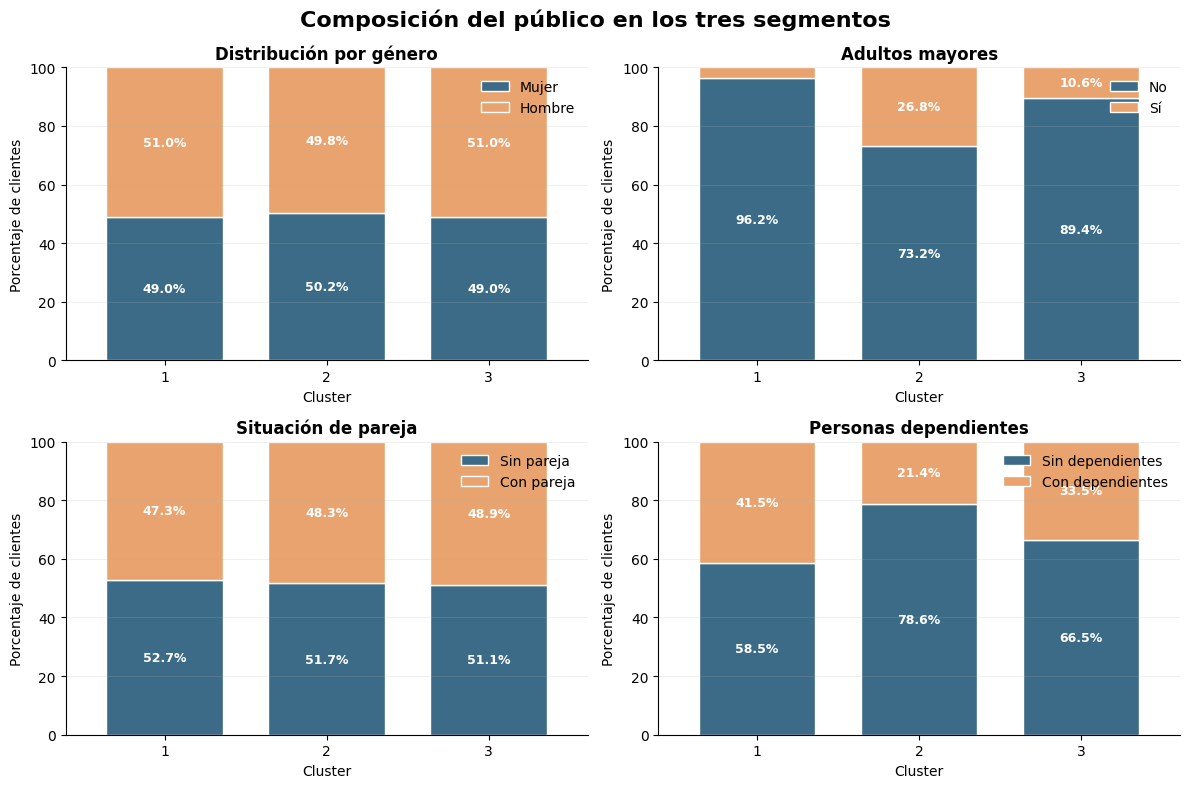

In [25]:
variables_publico = {
    "gender": (["Female", "Male"], ["Mujer", "Hombre"]),
    "SeniorCitizen": ([0, 1], ["No", "Sí"]),
    "Partner": (["No", "Yes"], ["Sin pareja", "Con pareja"]),
    "Dependents": (["No", "Yes"], ["Sin dependientes", "Con dependientes"]),
}

titulos_publico = {
    "gender": "Distribución por género",
    "SeniorCitizen": "Adultos mayores",
    "Partner": "Situación de pareja",
    "Dependents": "Personas dependientes",
}

colores_publico = ["#3B6B86", "#E8A36F"]
fig, ejes = plt.subplots(2, 2, figsize=(12, 8))

for (variable, (categorias, etiquetas)), eje in zip(
    variables_publico.items(), ejes.ravel()
):
    distribucion = pd.crosstab(
        segmentos["Cluster"],
        segmentos[variable],
        normalize="index",
    ).mul(100)

    distribucion = distribucion.reindex(
        columns=categorias,
        fill_value=0,
    )
    distribucion.columns = etiquetas

    distribucion.plot(
        kind="bar",
        stacked=True,
        ax=eje,
        color=colores_publico,
        width=0.72,
        edgecolor="white",
    )

    for grupo_barras in eje.containers:
        for barra in grupo_barras:
            valor = barra.get_height()
            if valor >= 8:
                eje.text(
                    barra.get_x() + barra.get_width() / 2,
                    barra.get_y() + valor / 2,
                    f"{valor:.1f}%",
                    ha="center",
                    va="center",
                    color="white",
                    fontsize=9,
                    fontweight="bold",
                )

    eje.set_title(titulos_publico[variable], fontweight="bold")
    eje.set_xlabel("Cluster")
    eje.set_ylabel("Porcentaje de clientes")
    eje.set_ylim(0, 100)
    eje.tick_params(axis="x", rotation=0)
    eje.legend(frameon=False, loc="upper right")
    eje.grid(axis="y", alpha=0.18)
    eje.grid(axis="x", visible=False)
    eje.spines["top"].set_visible(False)
    eje.spines["right"].set_visible(False)

fig.suptitle(
    "Composición del público en los tres segmentos",
    fontsize=16,
    fontweight="bold",
)
plt.tight_layout()
plt.show()

**Lectura para marketing.** Género y situación de pareja son muy similares entre los clusters: sus diferencias máximas son solo **1,19** y **1,57** puntos porcentuales.

Las diferencias más claras aparecen en el ciclo de vida del público. El cluster **2** tiene **26,83 %** de adultos mayores, frente a **3,81 %** en el cluster **1**. El cluster **1** alcanza **41,50 %** de clientes con dependientes, frente a **21,41 %** en el cluster **2**.

## G. Preparación de las características del modelo

In [26]:
datos_modelo = clientes.copy()

columnas_yes_no = ["PaperlessBilling", "Partner", "Dependents"]
for columna in columnas_yes_no:
    datos_modelo[columna] = datos_modelo[columna].map({"Yes": 1, "No": 0})

datos_modelo["gender"] = datos_modelo["gender"].map({"Female": 0, "Male": 1})

columnas_servicios = [*servicios_internet, "MultipleLines"]
for columna in columnas_servicios:
    datos_modelo[columna] = datos_modelo[columna].eq("Yes").astype(int)

In [27]:
columnas_categoricas = ["Type", "PaymentMethod", "InternetService"]
columnas_escalar = ["MonthlyCharges"]
columnas_numericas = [
    "NumServiciosInternet",
    "PaperlessBilling", "Partner", "Dependents", "gender",
    *columnas_servicios,
    "SeniorCitizen", "TieneInternet", "TieneTelefono",
    "SeguridadYSoporte", "StreamingCompleto",
]

caracteristicas = columnas_categoricas + columnas_escalar + columnas_numericas

X = datos_modelo[caracteristicas]
y = datos_modelo["Churn"]

assert len(caracteristicas) == 21
assert not X.isna().any().any()
assert set(y.unique()) == {0, 1}

print("Características candidatas:", X.shape[1])
print("Variables excluidas: customerID, EndDate, BeginDate y TotalCharges")

Características candidatas: 21
Variables excluidas: customerID, EndDate, BeginDate y TotalCharges


## H. División en entrenamiento, validación y prueba

In [28]:
X_train, X_temporal, y_train, y_temporal = train_test_split(
    X,
    y,
    test_size=0.40,
    stratify=y,
    random_state=SEMILLA,
)

X_valid, X_test, y_valid, y_test = train_test_split(
    X_temporal,
    y_temporal,
    test_size=0.50,
    stratify=y_temporal,
    random_state=SEMILLA,
)

In [29]:
resumen_division = pd.DataFrame({
    "Conjunto": ["Entrenamiento", "Validación", "Prueba"],
    "Clientes": [len(X_train), len(X_valid), len(X_test)],
    "Cancelaciones": [y_train.sum(), y_valid.sum(), y_test.sum()],
    "Tasa churn (%)": [
        y_train.mean() * 100,
        y_valid.mean() * 100,
        y_test.mean() * 100,
    ],
})

display(resumen_division.round(2))

,Conjunto,Clientes,Cancelaciones,Tasa churn (%)
0,Entrenamiento,4225,1121,26.53
1,Validación,1409,374,26.54
2,Prueba,1409,374,26.54


## I. Preprocesamiento con Pipeline

In [30]:
preprocesador = ColumnTransformer(
    transformers=[
        (
            "categoricas",
            crear_one_hot_encoder(),
            columnas_categoricas,
        ),
        ("cargo_mensual", StandardScaler(), columnas_escalar),
    ],
    remainder="passthrough",
)

print("El One-Hot y el escalado se ajustarán únicamente con X_train.")

El One-Hot y el escalado se ajustarán únicamente con X_train.


In [31]:
def entrenar_y_validar(nombre, clasificador):
    pipeline = Pipeline([
        ("preprocesamiento", clone(preprocesador)),
        ("clasificador", clasificador),
    ])

    pipeline.fit(X_train, y_train)
    probabilidades = pipeline.predict_proba(X_valid)[:, 1]
    predicciones = (probabilidades >= 0.50).astype(int)

    resultado = {
        "Modelo": nombre,
        "AUC-ROC validación": roc_auc_score(y_valid, probabilidades),
        "Recall validación": recall_score(y_valid, predicciones),
        "Precisión validación": precision_score(y_valid, predicciones),
    }

    return resultado, pipeline

## J. Modelos baseline sin balanceo

In [32]:
modelos_baseline = {
    "Regresión logística": LogisticRegression(
        max_iter=1000,
        random_state=SEMILLA,
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=SEMILLA,
        n_jobs=-1,
    ),
}

resultados_modelos = []
pipelines_entrenados = {}

for nombre, clasificador in modelos_baseline.items():
    resultado, pipeline = entrenar_y_validar(nombre, clasificador)
    resultados_modelos.append(resultado)
    pipelines_entrenados[nombre] = pipeline

display(pd.DataFrame(resultados_modelos).round(3))

,Modelo,AUC-ROC validación,Recall validación,Precisión validación
0,Regresión logística,0.844,0.537,0.646
1,Random Forest,0.802,0.468,0.583


## K. Desbalance y optimización controlada

Probamos `class_weight="balanced"` y unas pocas configuraciones. Esta búsqueda es deliberadamente pequeña para mantener el experimento claro y evitar una optimización innecesaria.

In [33]:
modelos_ajustados = {
    "Logística balanceada C=0.1": LogisticRegression(
        C=0.1, class_weight="balanced", max_iter=1000, random_state=SEMILLA
    ),
    "Logística balanceada C=1": LogisticRegression(
        C=1, class_weight="balanced", max_iter=1000, random_state=SEMILLA
    ),
    "Logística balanceada C=10": LogisticRegression(
        C=10, class_weight="balanced", max_iter=1000, random_state=SEMILLA
    ),
    "Random Forest balanceado profundidad=6": RandomForestClassifier(
        n_estimators=300, max_depth=6, min_samples_leaf=5,
        class_weight="balanced", random_state=SEMILLA, n_jobs=-1
    ),
    "Random Forest balanceado profundidad=10": RandomForestClassifier(
        n_estimators=300, max_depth=10, min_samples_leaf=3,
        class_weight="balanced", random_state=SEMILLA, n_jobs=-1
    ),
    "Random Forest balanceado sin límite": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=5,
        class_weight="balanced", random_state=SEMILLA, n_jobs=-1
    ),
}

for nombre, clasificador in modelos_ajustados.items():
    resultado, pipeline = entrenar_y_validar(nombre, clasificador)
    resultados_modelos.append(resultado)
    pipelines_entrenados[nombre] = pipeline

comparacion_modelos = (
    pd.DataFrame(resultados_modelos)
    .sort_values("AUC-ROC validación", ascending=False)
    .reset_index(drop=True)
)

display(comparacion_modelos.round(3))

,Modelo,AUC-ROC validación,Recall validación,Precisión validación
0,Regresión logística,0.844,0.537,0.646
1,Logística balanceada C=1,0.843,0.805,0.493
2,Logística balanceada C=10,0.843,0.805,0.489
3,Logística balanceada C=0.1,0.843,0.810,0.490
4,Random Forest balanceado profundidad=6,0.841,0.799,0.495
5,Random Forest balanceado profundidad=10,0.836,0.738,0.529
6,Random Forest balanceado sin límite,0.834,0.749,0.524
7,Random Forest,0.802,0.468,0.583


In [34]:
mejor_nombre = comparacion_modelos.loc[0, "Modelo"]
mejor_modelo = pipelines_entrenados[mejor_nombre]

mejor_auc_valid = comparacion_modelos.loc[0, "AUC-ROC validación"]

print("Modelo seleccionado:", mejor_nombre)
print(f"AUC-ROC de validación: {mejor_auc_valid:.3f}")

Modelo seleccionado: Regresión logística
AUC-ROC de validación: 0.844


### Selección del umbral con validación

In [35]:
probabilidades_valid = mejor_modelo.predict_proba(X_valid)[:, 1]
resultados_umbral = []

for umbral in np.arange(0.20, 0.71, 0.05):
    predicciones = (probabilidades_valid >= umbral).astype(int)
    resultados_umbral.append({
        "Umbral": umbral,
        "Recall": recall_score(y_valid, predicciones),
        "Precisión": precision_score(y_valid, predicciones, zero_division=0),
        "F1": f1_score(y_valid, predicciones),
    })

tabla_umbrales = pd.DataFrame(resultados_umbral)
display(tabla_umbrales.round(3))

,Umbral,Recall,Precisión,F1
0,0.20,0.882,0.462,0.607
1,0.25,0.826,0.486,0.612
2,0.30,0.786,0.520,0.626
3,0.35,0.746,0.554,0.636
4,0.40,0.695,0.592,0.640
5,0.45,0.642,0.619,0.630
6,0.50,0.537,0.646,0.587
7,0.55,0.441,0.655,0.527
8,0.60,0.332,0.663,0.442
9,0.65,0.219,0.732,0.337


In [36]:
umbrales_validos = tabla_umbrales.loc[tabla_umbrales["Recall"].ge(0.75)]

if len(umbrales_validos) > 0:
    fila_umbral = umbrales_validos.sort_values(
        ["Precisión", "Umbral"],
        ascending=[False, False],
    ).iloc[0]
else:
    fila_umbral = tabla_umbrales.loc[
        tabla_umbrales["F1"].idxmax()
    ]

umbral_elegido = float(fila_umbral["Umbral"])

print(f"Umbral elegido con validación: {umbral_elegido:.2f}")
print(f"Recall de validación: {fila_umbral['Recall']:.3f}")
print(f"Precisión de validación: {fila_umbral['Precisión']:.3f}")

Umbral elegido con validación: 0.30
Recall de validación: 0.786
Precisión de validación: 0.520


## L. Evaluación provisional de los modelos iniciales

Esta evaluación sirve como referencia para decidir si es necesario continuar. Todavía no representa el cierre definitivo del proyecto.

In [37]:
probabilidades_test = mejor_modelo.predict_proba(X_test)[:, 1]
predicciones_test = (probabilidades_test >= umbral_elegido).astype(int)

auc_test = roc_auc_score(y_test, probabilidades_test)
recall_test = recall_score(y_test, predicciones_test)
precision_test = precision_score(y_test, predicciones_test)
f1_test = f1_score(y_test, predicciones_test)
matriz_test = confusion_matrix(y_test, predicciones_test)

metricas_test = pd.DataFrame({
    "Métrica": ["AUC-ROC", "Recall", "Precisión", "F1", "Umbral"],
    "Resultado": [auc_test, recall_test, precision_test, f1_test, umbral_elegido],
})

display(metricas_test.round(3))

,Métrica,Resultado
0,AUC-ROC,0.809
1,Recall,0.770
2,Precisión,0.506
3,F1,0.611
4,Umbral,0.300


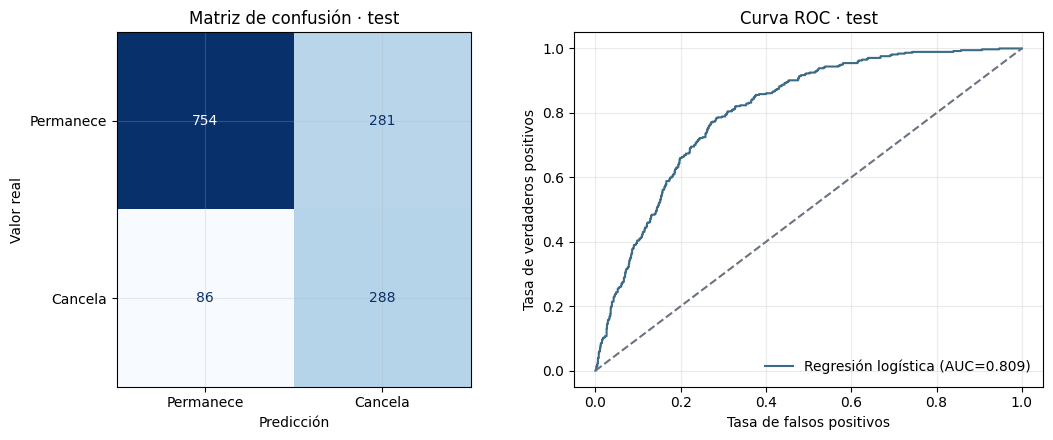

In [38]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4.5))

ConfusionMatrixDisplay(
    confusion_matrix=matriz_test,
    display_labels=["Permanece", "Cancela"],
).plot(ax=ejes[0], cmap="Blues", colorbar=False)
ejes[0].set_title("Matriz de confusión · test")
ejes[0].set_xlabel("Predicción")
ejes[0].set_ylabel("Valor real")

falsos_positivos, verdaderos_positivos, _ = roc_curve(
    y_test,
    probabilidades_test,
)
ejes[1].plot(
    falsos_positivos,
    verdaderos_positivos,
    color=COLOR_AZUL,
    label=f"{mejor_nombre} (AUC={auc_test:.3f})",
)
ejes[1].plot([0, 1], [0, 1], linestyle="--", color=COLOR_GRIS)
ejes[1].set_title("Curva ROC · test")
ejes[1].set_xlabel("Tasa de falsos positivos")
ejes[1].set_ylabel("Tasa de verdaderos positivos")
ejes[1].legend(frameon=False)

plt.tight_layout()
plt.show()

## M. Conclusión provisional y decisión de continuar

La **regresión logística** fue el mejor modelo inicial. En validación obtuvo un AUC-ROC de **0,844** y, al aplicarlo al conjunto de prueba, obtuvo **0,809**. El resultado era válido como punto de partida, pero permanecía en el nivel mínimo aceptable para el objetivo del proyecto.

El balanceo permitió detectar más cancelaciones, pero no elevó el AUC-ROC. Además, bajar el umbral a **0,30** mejoró el recall a **0,770**, a cambio de reducir la precisión. Esta fue una decisión comercial razonable: para una campaña de retención es preferible avisar a algunos clientes adicionales antes que dejar escapar una gran parte de las cancelaciones.

Como la regresión logística modela principalmente relaciones lineales y el Random Forest tampoco la superó, se decidió continuar con **Gradient Boosting**. Este algoritmo puede combinar gradualmente señales como contrato, método de pago, servicios y cargos, capturando relaciones que los modelos iniciales no identificaron.

Estas conclusiones se conservan porque explican por qué la optimización final era necesaria; no se reemplazan por el resultado posterior.

## N. Optimización final con Gradient Boosting

La optimización se mantiene deliberadamente pequeña: se prueban cuatro combinaciones fáciles de leer y se selecciona la de mayor AUC-ROC en validación.

Se incorpora `TotalCharges` porque es un dato de facturación acumulada disponible en el momento de analizar al cliente. Los once valores vacíos corresponden a cuentas sin historial de cobro y se completan con cero. **No se utilizan `BeginDate` ni `EndDate`**, por lo que el modelo no recibe fechas de inicio o cancelación.

In [39]:
datos_boost = datos_modelo.copy()
datos_boost["TotalCharges"] = datos_boost["TotalCharges"].fillna(0)

columnas_escalar_boost = ["MonthlyCharges", "TotalCharges"]
caracteristicas_boost = (
    columnas_categoricas + columnas_escalar_boost + columnas_numericas
)

X_boost = datos_boost[caracteristicas_boost]

# Conservamos exactamente los mismos clientes en cada conjunto.
X_train_boost = X_boost.loc[X_train.index]
X_valid_boost = X_boost.loc[X_valid.index]
X_test_boost = X_boost.loc[X_test.index]

preprocesador_boost = ColumnTransformer(
    transformers=[
        (
            "categoricas",
            crear_one_hot_encoder(),
            columnas_categoricas,
        ),
        ("cargos", StandardScaler(), columnas_escalar_boost),
    ],
    remainder="passthrough",
)

assert "BeginDate" not in caracteristicas_boost
assert "EndDate" not in caracteristicas_boost
assert not X_boost.isna().any().any()

print("Características del Gradient Boosting:", X_boost.shape[1])
print("Fechas excluidas: BeginDate y EndDate")

Características del Gradient Boosting: 22
Fechas excluidas: BeginDate y EndDate


In [40]:
configuraciones_boost = [
    {"Árboles": 100, "Learning rate": 0.05, "Profundidad": 2},
    {"Árboles": 200, "Learning rate": 0.05, "Profundidad": 1},
    {"Árboles": 300, "Learning rate": 0.08, "Profundidad": 1},
    {"Árboles": 300, "Learning rate": 0.10, "Profundidad": 1},
]

resultados_boost = []
modelos_boost = {}

for configuracion in configuraciones_boost:
    nombre = (
        f"GB árboles={configuracion['Árboles']}, "
        f"lr={configuracion['Learning rate']}, "
        f"profundidad={configuracion['Profundidad']}"
    )

    pipeline_boost = Pipeline([
        ("preprocesamiento", clone(preprocesador_boost)),
        (
            "clasificador",
            GradientBoostingClassifier(
                n_estimators=configuracion["Árboles"],
                learning_rate=configuracion["Learning rate"],
                max_depth=configuracion["Profundidad"],
                min_samples_leaf=10,
                random_state=SEMILLA,
            ),
        ),
    ])

    pipeline_boost.fit(X_train_boost, y_train)
    probabilidades = pipeline_boost.predict_proba(X_valid_boost)[:, 1]
    predicciones = (probabilidades >= 0.50).astype(int)

    resultados_boost.append({
        "Modelo": nombre,
        "AUC-ROC validación": roc_auc_score(y_valid, probabilidades),
        "Recall validación": recall_score(y_valid, predicciones),
        "Precisión validación": precision_score(y_valid, predicciones),
    })
    modelos_boost[nombre] = pipeline_boost

comparacion_boost = (
    pd.DataFrame(resultados_boost)
    .sort_values("AUC-ROC validación", ascending=False)
    .reset_index(drop=True)
)

display(comparacion_boost.round(3))

,Modelo,AUC-ROC validación,Recall validación,Precisión validación
0,"GB árboles=300, lr=0.1, profundidad=1",0.860,0.524,0.695
1,"GB árboles=300, lr=0.08, profundidad=1",0.859,0.516,0.692
2,"GB árboles=100, lr=0.05, profundidad=2",0.855,0.452,0.693
3,"GB árboles=200, lr=0.05, profundidad=1",0.853,0.422,0.699


In [41]:
nombre_boost_final = comparacion_boost.loc[0, "Modelo"]
modelo_boost_final = modelos_boost[nombre_boost_final]

probabilidades_valid_boost = modelo_boost_final.predict_proba(
    X_valid_boost
)[:, 1]

resultados_umbral_boost = []
for umbral in np.arange(0.20, 0.71, 0.05):
    predicciones = (probabilidades_valid_boost >= umbral).astype(int)
    resultados_umbral_boost.append({
        "Umbral": umbral,
        "Recall": recall_score(y_valid, predicciones),
        "Precisión": precision_score(
            y_valid, predicciones, zero_division=0
        ),
        "F1": f1_score(y_valid, predicciones),
    })

tabla_umbrales_boost = pd.DataFrame(resultados_umbral_boost)
umbrales_validos_boost = tabla_umbrales_boost.loc[
    tabla_umbrales_boost["Recall"].ge(0.75)
]

if len(umbrales_validos_boost) > 0:
    fila_umbral_boost = umbrales_validos_boost.sort_values(
        ["Precisión", "Umbral"], ascending=[False, False]
    ).iloc[0]
else:
    fila_umbral_boost = tabla_umbrales_boost.loc[
        tabla_umbrales_boost["F1"].idxmax()
    ]

umbral_boost = float(fila_umbral_boost["Umbral"])

print("Modelo final:", nombre_boost_final)
print(f"Umbral elegido: {umbral_boost:.2f}")
display(tabla_umbrales_boost.round(3))

Modelo final: GB árboles=300, lr=0.1, profundidad=1
Umbral elegido: 0.35


,Umbral,Recall,Precisión,F1
0,0.20,0.888,0.472,0.617
1,0.25,0.850,0.502,0.631
2,0.30,0.810,0.537,0.646
3,0.35,0.762,0.571,0.653
4,0.40,0.695,0.613,0.652
5,0.45,0.623,0.653,0.637
6,0.50,0.524,0.695,0.598
7,0.55,0.393,0.717,0.508
8,0.60,0.307,0.782,0.441
9,0.65,0.251,0.839,0.387


### Justificación comercial del umbral final

El valor **0,35** no se eligió manualmente. Se probaron umbrales entre 0,20 y 0,70 y se conservaron aquellos capaces de detectar al menos el **75 %** de las cancelaciones en validación. Entre los candidatos válidos se escogió el de mayor precisión.

El umbral 0,35 ofreció un recall de **0,762** y una precisión de **0,571** en validación. Es el punto más exigente que todavía cumple el objetivo de detectar aproximadamente tres de cada cuatro cancelaciones. La decisión acepta algunas falsas alarmas porque, para retención, se considera menos perjudicial contactar a un cliente adicional que no identificar una posible baja. Cuando existan costes reales de contacto, descuentos y pérdida de clientes, el umbral deberá recalibrarse económicamente.

In [42]:
probabilidades_test_boost = modelo_boost_final.predict_proba(
    X_test_boost
)[:, 1]
predicciones_test_boost = (
    probabilidades_test_boost >= umbral_boost
).astype(int)

auc_test_boost = roc_auc_score(y_test, probabilidades_test_boost)
recall_test_boost = recall_score(y_test, predicciones_test_boost)
precision_test_boost = precision_score(y_test, predicciones_test_boost)
f1_test_boost = f1_score(y_test, predicciones_test_boost)
matriz_test_boost = confusion_matrix(y_test, predicciones_test_boost)

metricas_test_boost = pd.DataFrame({
    "Métrica": ["AUC-ROC", "Recall", "Precisión", "F1", "Umbral"],
    "Resultado": [
        auc_test_boost,
        recall_test_boost,
        precision_test_boost,
        f1_test_boost,
        umbral_boost,
    ],
})

display(metricas_test_boost.round(3))
print(
    "Mejora del AUC-ROC frente a la evaluación provisional:",
    f"{auc_test_boost - auc_test:.3f}",
)

,Métrica,Resultado
0,AUC-ROC,0.837
1,Recall,0.741
2,Precisión,0.544
3,F1,0.627
4,Umbral,0.350


Mejora del AUC-ROC frente a la evaluación provisional: 0.029


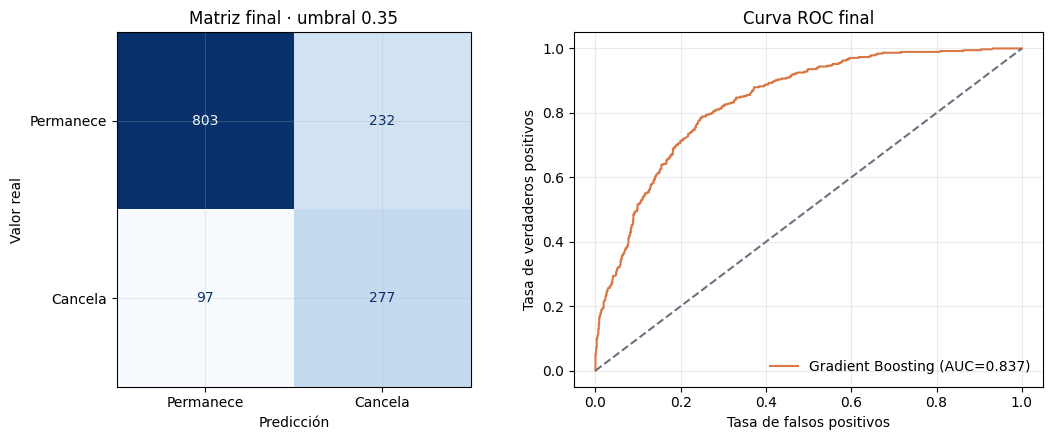

In [43]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4.5))

ConfusionMatrixDisplay(
    confusion_matrix=matriz_test_boost,
    display_labels=["Permanece", "Cancela"],
).plot(ax=ejes[0], cmap="Blues", colorbar=False)
ejes[0].set_title(f"Matriz final · umbral {umbral_boost:.2f}")
ejes[0].set_xlabel("Predicción")
ejes[0].set_ylabel("Valor real")

falsos_positivos, verdaderos_positivos, _ = roc_curve(
    y_test,
    probabilidades_test_boost,
)
ejes[1].plot(
    falsos_positivos,
    verdaderos_positivos,
    color=COLOR_NARANJA,
    label=f"Gradient Boosting (AUC={auc_test_boost:.3f})",
)
ejes[1].plot([0, 1], [0, 1], linestyle="--", color=COLOR_GRIS)
ejes[1].set_title("Curva ROC final")
ejes[1].set_xlabel("Tasa de falsos positivos")
ejes[1].set_ylabel("Tasa de verdaderos positivos")
ejes[1].legend(frameon=False)

plt.tight_layout()
plt.show()

## O. Interpretación de las variables del modelo final

In [44]:
preprocesador_final = modelo_boost_final.named_steps["preprocesamiento"]
clasificador_final = modelo_boost_final.named_steps["clasificador"]
encoder_final = preprocesador_final.named_transformers_["categoricas"]

try:
    nombres_categorias = encoder_final.get_feature_names_out(
        columnas_categoricas
    )
except AttributeError:
    nombres_categorias = encoder_final.get_feature_names(
        columnas_categoricas
    )

nombres_variables = np.concatenate([
    nombres_categorias,
    columnas_escalar_boost,
    columnas_numericas,
])

assert len(nombres_variables) == len(
    clasificador_final.feature_importances_
)

importancia = pd.DataFrame({
    "Variable": nombres_variables,
    "Importancia": clasificador_final.feature_importances_,
})

importancia = importancia.sort_values("Importancia", ascending=False)
display(importancia.head(15).round(3))

,Variable,Importancia
0,Type_Month-to-month,0.433
8,InternetService_Fiber optic,0.179
11,TotalCharges,0.162
5,PaymentMethod_Electronic check,0.089
25,TieneInternet,0.022
13,PaperlessBilling,0.021
9,InternetService_No,0.020
10,MonthlyCharges,0.015
2,Type_Two year,0.012
17,OnlineSecurity,0.010


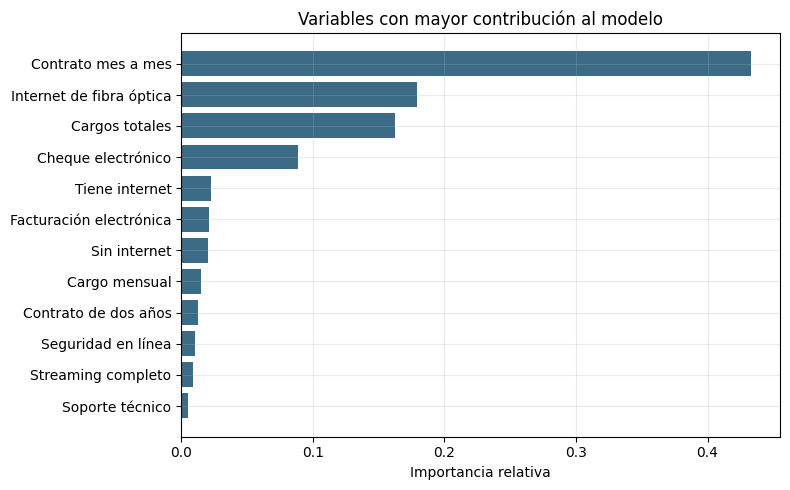

In [45]:
principales = importancia.head(12).copy()

nombres_legibles = {
    "Type_Month-to-month": "Contrato mes a mes",
    "InternetService_Fiber optic": "Internet de fibra óptica",
    "TotalCharges": "Cargos totales",
    "PaymentMethod_Electronic check": "Cheque electrónico",
    "TieneInternet": "Tiene internet",
    "PaperlessBilling": "Facturación electrónica",
    "InternetService_No": "Sin internet",
    "MonthlyCharges": "Cargo mensual",
    "Type_Two year": "Contrato de dos años",
    "OnlineSecurity": "Seguridad en línea",
    "StreamingCompleto": "Streaming completo",
    "TechSupport": "Soporte técnico",
}

principales["Variable legible"] = principales["Variable"].replace(
    nombres_legibles
)
principales = principales.sort_values("Importancia")

fig, eje = plt.subplots(figsize=(8, 5))
eje.barh(
    principales["Variable legible"],
    principales["Importancia"],
    color=COLOR_AZUL,
)
eje.set_title("Variables con mayor contribución al modelo")
eje.set_xlabel("Importancia relativa")
eje.set_ylabel("")
plt.tight_layout()
plt.show()

## P. Comparación final entre clustering y predicción

In [46]:
comparacion_cluster_modelo = pd.DataFrame(index=X_test.index)
comparacion_cluster_modelo["Cluster"] = segmentos.loc[X_test.index, "Cluster"]
comparacion_cluster_modelo["Churn_real"] = y_test
comparacion_cluster_modelo["Probabilidad"] = probabilidades_test_boost
comparacion_cluster_modelo["Prediccion"] = predicciones_test_boost
comparacion_cluster_modelo["Cancelacion_detectada"] = (
    comparacion_cluster_modelo["Churn_real"].eq(1)
    & comparacion_cluster_modelo["Prediccion"].eq(1)
).astype(int)

comparacion_por_cluster = (
    comparacion_cluster_modelo.groupby("Cluster")
    .agg(
        Clientes=("Churn_real", "size"),
        Cancelaciones=("Churn_real", "sum"),
        Tasa_churn=("Churn_real", "mean"),
        Probabilidad_media=("Probabilidad", "mean"),
        Cancelaciones_detectadas=("Cancelacion_detectada", "sum"),
    )
)

comparacion_por_cluster["Recall"] = (
    comparacion_por_cluster["Cancelaciones_detectadas"]
    / comparacion_por_cluster["Cancelaciones"]
)

for columna in ["Tasa_churn", "Probabilidad_media", "Recall"]:
    comparacion_por_cluster[columna] *= 100

display(comparacion_por_cluster.round(2))

,Clientes,Cancelaciones,Tasa_churn,Probabilidad_media,Cancelaciones_detectadas,Recall
Cluster,,,,,,
1,317,27,8.52,9.94,11,40.74
2,624,266,42.63,42.01,220,82.71
3,468,81,17.31,17.93,46,56.79


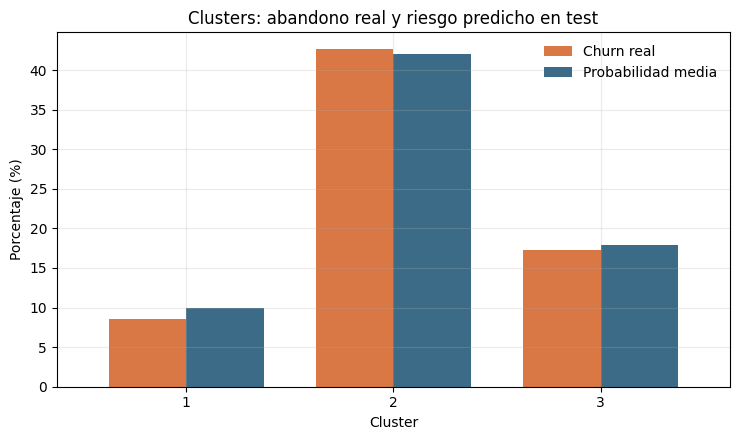

In [47]:
datos_grafica = comparacion_por_cluster[
    ["Tasa_churn", "Probabilidad_media"]
].copy()

datos_grafica.index = datos_grafica.index.astype(str)
datos_grafica = datos_grafica.rename(columns={
    "Tasa_churn": "Churn real",
    "Probabilidad_media": "Probabilidad media",
})

fig, eje = plt.subplots(figsize=(7.5, 4.5))
datos_grafica.plot(
    kind="bar",
    ax=eje,
    width=0.75,
    color=[COLOR_NARANJA, COLOR_AZUL],
    rot=0,
)

eje.set_title("Clusters: abandono real y riesgo predicho en test")
eje.set_xlabel("Cluster")
eje.set_ylabel("Porcentaje (%)")
eje.legend(frameon=False)

plt.tight_layout()
plt.show()

# Etapa 3 · Informe de solución

## Informe ejecutivo para marketing

**Punto de partida.** La regresión logística fue el mejor modelo inicial. Obtuvo un AUC-ROC de **0,844 en validación** y **0,809 en prueba**. El balanceo elevó el recall, pero no mejoró el AUC-ROC. Este resultado se mantuvo como referencia y justificó probar un algoritmo capaz de encontrar relaciones no lineales.

**Modelo final.** Se eligió un **Gradient Boosting de 300 árboles**, `learning_rate=0.10`, profundidad `1` y `min_samples_leaf=10`. Fue la mejor de cuatro configuraciones visibles y obtuvo un AUC-ROC de **0,860 en validación**.

**Resultado de prueba.** En el conjunto de prueba obtuvo un AUC-ROC de **0,837**, un recall de **0,741**, una precisión de **0,544** y un F1 de **0,627**. Detectó **277 de 374** cancelaciones y dejó sin detectar **97**. El AUC-ROC mejoró **0,029** frente a la solución provisional.

**Lectura del objetivo.** El resultado de validación entra en la categoría *Muy bueno* definida para el proyecto. La prueba final permanece en la categoría *Bueno*. Por tanto, existe una mejora real, pero no se afirma que el modelo haya alcanzado 0,85 en datos de prueba.

**Decisión de negocio sobre el umbral.** Se probaron valores entre 0,20 y 0,70. Se exigió un recall mínimo de **0,75 en validación** y, entre los umbrales que cumplieron esa condición, se eligió el de mayor precisión. El resultado fue **0,35**, con recall **0,762** y precisión **0,571** en validación. Esta regla busca detectar aproximadamente tres de cada cuatro cancelaciones, aceptando algunos contactos adicionales. El umbral debe recalibrarse cuando se conozcan los costes de campaña, descuentos y pérdida de clientes.

**Segmentación comercial.** El clustering encontró tres segmentos sin utilizar `Churn`. El cluster **2** concentra el mayor riesgo: en prueba presentó un churn real de **42,63 %** y una probabilidad media predicha de **42,01 %**. El cluster **1** fue de menor riesgo (**8,52 %** real y **9,94 %** predicho) y el cluster **3** mantuvo un perfil intermedio (**17,31 %** real y **17,93 %** predicho).

| Cluster | Churn real en prueba | Probabilidad media | Recall del modelo |
|---:|---:|---:|---:|
| 1 | 8,52 % | 9,94 % | 40,74 % |
| 2 | 42,63 % | 42,01 % | 82,71 % |
| 3 | 17,31 % | 17,93 % | 56,79 % |

**Coherencia comercial.** El modelo y el clustering se construyeron de manera independiente, pero ordenan los grupos de la misma forma. El cluster 2 es el público prioritario para retención y también el segmento donde el modelo detecta mejor las cancelaciones.

**Variables principales.** Las señales más importantes del modelo fueron contrato mensual, internet por fibra óptica, cargos totales y pago mediante cheque electrónico. Son asociaciones predictivas; no demuestran que una característica cause el abandono.

**Uso recomendado.** Marketing puede utilizar la probabilidad para ordenar a quién contactar y los clusters para adaptar el mensaje u oferta al perfil comercial. Género, pareja, dependientes y condición de adulto mayor se conservan en el análisis para describir el público, pero no deben interpretarse como causas.

**Limitaciones.** `TotalCharges` se utiliza bajo el supuesto de que el valor acumulado está disponible en el momento de predecir. No se utilizan `BeginDate`, `EndDate` ni duraciones calculadas con fechas. La base contiene una sola fila por cliente y no permite estimar ingresos salvados ni efectos causales sin datos de campañas reales.

## Conclusión técnica

El proyecto conserva una historia metodológica completa. Primero se construyó una solución sencilla con regresión logística y Random Forest. Su mejor resultado de prueba fue **0,809**, suficiente como referencia pero por debajo del objetivo. Esa conclusión provisional explica la incorporación posterior de Gradient Boosting; no fue eliminada ni presentada retrospectivamente como un fracaso.

La búsqueda final fue controlada y legible: cuatro configuraciones, selección por AUC-ROC de validación y un único criterio comercial para el umbral. Gradient Boosting alcanzó **0,860 en validación** y **0,837 en prueba**, una mejora de **0,029** frente a la regresión logística evaluada bajo la misma división.

La selección del umbral separa dos decisiones distintas: el AUC-ROC elige el modelo por su capacidad de ordenar riesgos y el umbral transforma esas probabilidades en una lista de contacto. El umbral **0,35** fue el de mayor precisión entre los que alcanzaron al menos **75 % de recall en validación**. En prueba logró un recall de **0,741**, mostrando una pequeña brecha de generalización que debe comunicarse con transparencia.

La segmentación y la predicción permanecen separadas: K-Means no utiliza `Churn` y el Gradient Boosting no utiliza la etiqueta de cluster. Su coincidencia posterior —riesgo bajo, alto e intermedio en el mismo orden— fortalece la interpretación comercial sin introducir fuga de información.

El modelo final no utiliza `BeginDate` ni `EndDate`. `TotalCharges` se considera información de facturación disponible al momento de puntuar al cliente; si ese supuesto no se cumple en producción, deberá excluirse y reentrenarse el modelo.

El resultado final mejora de forma clara el punto de partida, aunque el AUC-ROC de prueba todavía no alcanza **0,85**. La entrega debe presentarlo como un modelo **bueno y útil para priorización**, no como una garantía perfecta. El siguiente avance dependería más de incorporar datos temporales correctamente construidos —snapshots históricos anteriores a la cancelación— que de seguir aumentando la complejidad del código.